In [4]:
!pip install torch
import pandas as pd
import numpy as np


In [44]:
df=pd.read_csv("powerplant_data.csv")

In [45]:
df.head()

,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43


In [46]:
#at= temprature,
#v=vaccum,
#ap=pressure
#rh=humidity
#pe=produced energy
df.isnull().sum()

AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

In [47]:
x=df.drop("PE",axis=1)
y=df["PE"]

0    480.48
1    445.75
2    438.76
3    453.09
4    464.43
Name: PE, dtype: float64

In [48]:
#convert dataset into pytorch dataset
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(
    x,y,test_size=0.2,random_state=42
)


In [49]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
x_train_scaled=scaler.fit_transform(x_train)
x_test_scaled=scaler.fit_transform(x_test)

In [50]:
#converting into tensor dataset
import torch
import torch.nn as nn
x_train_tensor=torch.tensor(x_train_scaled,dtype=torch.float32)
x_test_tensor=torch.tensor(x_test_scaled,dtype=torch.float32)

y_train_tensor=torch.tensor(y_train.values,dtype=torch.float32).view(-1,1)
y_test_tensor=torch.tensor(y_test.values,dtype=torch.float32).view(-1,1)

#the reason .values and .view is used for converting y into tensor because we did'nt scale y values and also there is a difference in the type in which x and y values are stored. x is np.array and y is pandas

In [51]:
type(x_train_scaled)

numpy.ndarray

In [52]:
type(y_train)

pandas.core.series.Series

In [53]:
from torch.utils.data import TensorDataset,DataLoader

train_dataset=TensorDataset(x_train_tensor,y_train_tensor)
test_dataset=TensorDataset(x_test_tensor,y_test_tensor)

In [54]:
train_loader=DataLoader(train_dataset,batch_size=32,shuffle=True)
test_loader=DataLoader(test_dataset,batch_size=32)

deep learning , creating artifical neural network

In [55]:
class ANN(nn.Module):
    def __init__(self):
        super(ANN,self).__init__()
        self.model=nn.Sequential(
        #1st hidden layer
        nn.Linear(x_train.shape[1],6),
        nn.ReLU(),

        #2nd hidden layer
        nn.Linear(6,6),
        nn.ReLU(),

        #output layer
        nn.Linear(6,1),
    )
    def forward(self,x):
        return self.model(x)

In [56]:
import torch.optim as optim
model=ANN()

crietrion=nn.MSELoss() #loss 
optimizer=optim.Adam(model.parameters())#optimizer



training ANN model

In [57]:
test_losses = []
train_losses=[]

best_val_loss=float("inf")

epochs=100
for epoch in range(epochs):
    model.train()
    running_loss=0.0 # total training loss for 1 epoch

    for xb,yb in train_loader:
        
        #xb = features of 1 batch
        #yb = labels of 1 batch
        optimizer.zero_grad()
        outputs=model(xb)#predicted outputs for this batch
        loss=crietrion(outputs,yb)#computer loss
        loss.backward()#back proption compute graidents
        optimizer.step()#params update

        running_loss+=loss.item()
    epoch_train_loss=running_loss/len(train_loader)
    train_losses.append(epoch_train_loss)

    #validation
    model.eval()
    running_validation_loss=0.0
    with torch.no_grad(): #no gradients computation
        for xb,yb in test_loader:
            outputs=model(xb)
            loss=crietrion(outputs,yb)
            running_validation_loss+=loss.item()

    epoch_test_loss=running_validation_loss/len(test_loader)
    test_losses.append(epoch_test_loss)
   

    print(f"epoch${epoch+1}/{epochs}==>training loss=${epoch_train_loss} & testing loss=${epoch_test_loss}")
    
    if epoch_test_loss<best_val_loss:
        best_val_loss=epoch_test_loss
        torch.save(model.state_dict(),"best_model.pt")#.pt or .pth
       

epoch$1/100==>training loss=$206002.02975260417 & testing loss=$204773.3390625


epoch$2/100==>training loss=$199542.037109375 & testing loss=$190136.51901041667


epoch$3/100==>training loss=$172655.32630208333 & testing loss=$150540.23385416667


epoch$4/100==>training loss=$122849.97132161459 & testing loss=$95012.42630208333


epoch$5/100==>training loss=$72144.11363932291 & testing loss=$53001.8025390625


...

epoch$96/100==>training loss=$19.284694310029348 & testing loss=$18.09096926053365


epoch$97/100==>training loss=$19.25886545976003 & testing loss=$17.54678316116333


epoch$98/100==>training loss=$19.35596477985382 & testing loss=$17.436989116668702


epoch$99/100==>training loss=$19.291624238093693 & testing loss=$17.65381553967794


epoch$100/100==>training loss=$19.22075831492742 & testing loss=$17.422626280784606


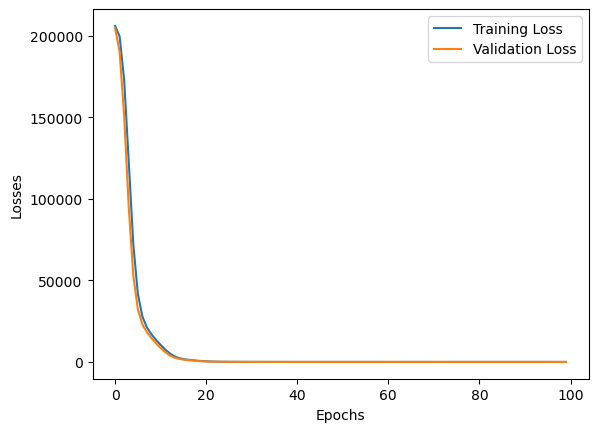

In [58]:
import matplotlib.pyplot as plt

loss_df = pd.DataFrame({
    "Training Loss": train_losses, 
    "Validation Loss": test_losses  # Updated key to match the plot code
})

plt.plot(loss_df["Training Loss"], label="Training Loss")
plt.plot(loss_df["Validation Loss"], label="Validation Loss") # Now matches the DataFrame key
plt.xlabel("Epochs")
plt.ylabel("Losses")
plt.legend()
plt.show()

In [59]:
#loading the best model
model.load_state_dict(torch.load("best_model.pt"))

<All keys matched successfully>

In [60]:
#evaluate model
model.eval()
with torch.no_grad():
    train_pred=model(x_train_tensor)
    test_pred=model(x_test_tensor)

    train_mse_loss=crietrion(train_pred,y_train_tensor)
    test_mse_loss=crietrion(test_pred,y_test_tensor)
print("training mse:",train_mse_loss.item())
print("testing mse:",test_mse_loss.item())


training mse: 19.021499633789062
testing mse: 17.384937286376953


In [61]:
from sklearn.metrics import r2_score
print("r2 score=",r2_score(y_test,test_pred))

r2 score= 0.9392441273678706


In [62]:
actual_df=pd.DataFrame(y_test.values,columns=["Actual Values"])
predicated_df=pd.DataFrame(test_pred.numpy(),columns=["predicated values"])
pd.concat([predicated_df,actual_df],axis=1)

,predicated values,Actual Values
0,436.478302,433.27
1,436.569397,438.16
2,460.033539,458.42
3,476.355499,480.82
4,438.511475,441.41
...,...,...
1909,450.698822,456.70
1910,433.749481,438.04
1911,467.634918,467.80
1912,433.176483,437.14
